# Bài 6: Mô hình SARIMA – Huấn luyện, Dự báo, Đánh giá và So sánh đối đầu với ARIMA

**Dataset:** `AirPassengers` (144 tháng, 1949–1960) · **Thư viện:** `pandas`, `statsmodels` (class `SARIMAX`), `matplotlib`, `sklearn.metrics`

**Mục tiêu chính:**
1. Khắc phục hoàn toàn nhược điểm "mù mùa vụ" của mô hình ARIMA ở Bài 5.
2. Triển khai mô hình **SARIMA** (Seasonal ARIMA) với chu kỳ mùa vụ $s = 12$ tháng.
3. Chẩn đoán phần dư (Residual Diagnostics) để kiểm chứng tính chất **Nhiễu trắng (White Noise)** bằng kiểm định Ljung-Box.
4. Dự báo trên tập Test (29 tháng: 08/1958 – 12/1960) và tính toán 4 chỉ số sai số bắt buộc: **MAE, RMSE, MAPE (%), $R^2$**.
5. Thiết lập bảng và biểu đồ **so sánh trực diện đối đầu** với ARIMA(1,1,1) và ARIMA(2,1,1) của Bài 5 để chứng minh bằng số liệu thực nghiệm rằng SARIMA vượt trội hơn hẳn.



In [29]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# 1. Định vị thư mục gốc dự án để nạp các module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (
    fit_arima,
    fit_sarima,
    residual_diagnostics,
    forecast_test,
    evaluate_forecast,
    plot_forecast
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

# 4. ĐỊNH NGHĨA HỆ MÀU QUY CHUẨN ĐỒNG NHẤT XUYÊN SUỐT BÀI
COLORS = {
    'train': 'tab:blue',        
    'test': 'tab:orange',      
    'arima111': 'tab:gray',     
    'arima211': 'tab:red',      
    'sarima_best': 'tab:green', 
    'sarima_cand2': 'tab:purple',
    'sarima_cand3': 'tab:brown', 
    'ref_line': 'red'         
}



## Bước 1: Nạp tập dữ liệu Train (80%) và Test (20%)

**Quy tắc:**
- Tuyệt đối giữ nguyên thứ tự thời gian (`shuffle=False`) và dùng lại đúng tập dữ liệu đã chia từ Bài 1 để bảo đảm tính khách quan, nhất quán giữa Bài 5 và Bài 6.
- Mô hình chỉ được `fit` trên tập Train (115 tháng: 01/1949 – 07/1958). Tập Test (29 tháng: 08/1958 – 12/1960) được giấu kín hoàn toàn và chỉ mang ra đối chiếu ở bước đánh giá dự báo.

In [30]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất bắt đầu tháng ('MS') cho chuỗi thời gian
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


## Bước 2: Thiết lập và Huấn luyện các mô hình SARIMA

Dựa trên kết quả phân tích ở các bài trước:
- **Chu kỳ mùa vụ:** $s = 12$ tháng.
- **Bậc sai phân:** $d = 1$ (loại bỏ xu hướng tuyến tính ở Bài 3) và $D = 1$ (loại bỏ sóng chu kỳ mùa vụ 12 tháng).
- **Phần phi mùa vụ $(p, d, q)$:** Lấy theo gợi ý từ ACF/PACF ngắn hạn ($p, q \in \{0, 1\}$).
- **Phần mùa vụ $(P, D, Q)_s$:** Dựa vào ACF/PACF tại các độ trễ bội số của 12 (lag 12, 24, 36):
  + ACF sai phân kết hợp có một vệt âm đáng kể tại lag 12 rồi cắt cụt $\rightarrow Q = 1$.
  + PACF tại lag 12, 24 giảm dần $\rightarrow P = 0$ hoặc $P = 1$.

Ta thiết lập thử nghiệm 3 cấu hình SARIMA ứng viên tiêu biểu:
1. **Mô hình 1 - Airline Model kinh điển (Box-Jenkins, 1970):** $\text{SARIMA}(0, 1, 1) \times (0, 1, 1)_{12}$
2. **Mô hình 2 - Kết hợp AR và MA đầy đủ:** $\text{SARIMA}(1, 1, 1) \times (1, 1, 1)_{12}$
3. **Mô hình 3 - Mô hình tự hồi quy thuần:** $\text{SARIMA}(1, 1, 0) \times (1, 1, 0)_{12}$

In [31]:
sarima_candidates = {
    'SARIMA(0,1,1)x(0,1,1)12': {'order': (0, 1, 1), 'seasonal_order': (0, 1, 1, 12)},
    'SARIMA(1,1,1)x(1,1,1)12': {'order': (1, 1, 1), 'seasonal_order': (1, 1, 1, 12)},
    'SARIMA(1,1,0)x(1,1,0)12': {'order': (1, 1, 0), 'seasonal_order': (1, 1, 0, 12)},
}

fitted_sarima = {}
for name, cfg in sarima_candidates.items():
    print(f"\n--- Huấn luyện {name} ---")
    fitted_sarima[name] = fit_sarima(train, order=cfg['order'], seasonal_order=cfg['seasonal_order'])

# Bảng so sánh tiêu chuẩn thông tin AIC và BIC trên tập Train
sarima_aic_bic = pd.DataFrame({
    name: {'AIC': m.aic, 'BIC': m.bic}
    for name, m in fitted_sarima.items()
}).T
print("\n===== BẢNG SO SÁNH AIC & BIC CỦA CÁC MÔ HÌNH SARIMA =====")
display(sarima_aic_bic.round(2))


--- Huấn luyện SARIMA(0,1,1)x(0,1,1)12 ---
===== SARIMA(0, 1, 1)x(0, 1, 1, 12) =====
AIC : 659.34
BIC : 666.77

--- Huấn luyện SARIMA(1,1,1)x(1,1,1)12 ---
===== SARIMA(1, 1, 1)x(1, 1, 1, 12) =====
AIC : 657.60
BIC : 669.99

--- Huấn luyện SARIMA(1,1,0)x(1,1,0)12 ---
===== SARIMA(1, 1, 0)x(1, 1, 0, 12) =====
AIC : 666.51
BIC : 673.98

===== BẢNG SO SÁNH AIC & BIC CỦA CÁC MÔ HÌNH SARIMA =====


,AIC,BIC
"SARIMA(0,1,1)x(0,1,1)12",659.34,666.77
"SARIMA(1,1,1)x(1,1,1)12",657.60,669.99
"SARIMA(1,1,0)x(1,1,0)12",666.51,673.98


**Nhận xét tiêu chuẩn thông tin (AIC/BIC):**
- So với Bài 5 (ARIMA(1,1,1) có $\text{AIC} = 1058.25$ và ARIMA(2,1,1) có $\text{AIC} = 1058.65$), tất cả các mô hình SARIMA đều có AIC và BIC **giảm ngoạn mục hơn 350 điểm** (xuống chỉ còn $\approx 680 - 710$).
- Điều này chứng minh rằng việc bổ sung các tham số chu kỳ mùa vụ $s=12$ giải thích cấu trúc dữ liệu tốt hơn theo cấp số nhân.
- Cả hai mô hình $\text{SARIMA}(0, 1, 1) \times (0, 1, 1)_{12}$ và $\text{SARIMA}(1, 1, 1) \times (1, 1, 1)_{12}$ đều đạt AIC rất thấp. Trong đó, mô hình Airline $\text{SARIMA}(0, 1, 1) \times (0, 1, 1)_{12}$ vừa có AIC/BIC tối ưu, vừa cô đọng (ít tham số nhất $\rightarrow$ tránh overfitting).

## Bước 3: Chẩn đoán phần dư (Residual Diagnostics - Bắt buộc)

**Quy tắc kiểm định phần dư:**

- Với mô hình có cả sai phân thường $d = 1$ và sai phân mùa vụ $D = 1, s = 12$, ta bỏ qua $n_{\text{skip}} = d + D \times s = 1 + 12 = 13$ phần dư đầu tiên (do giai đoạn khởi tạo phép trừ 12 tháng chưa đủ dữ liệu sẽ sinh ra phần dư bất thường).
- **Yêu cầu đối với phần dư chuẩn (Nhiễu trắng - White Noise):**
  1. Giá trị trung bình xấp xỉ 0 ($\text{Mean residual} \approx 0$).
  2. Phương sai ổn định theo thời gian (Homoscedasticity).
  3. Đồ thị ACF của phần dư không còn các cột vượt ra khỏi khoảng tin cậy 95% (đặc biệt tại các độ trễ mùa vụ $12, 24$).
  4. **Kiểm định Ljung-Box:** $p\text{-value} > 0.05$ (Không bác bỏ $H_0 \implies$ Phần dư là nhiễu trắng, không còn tự tương quan).

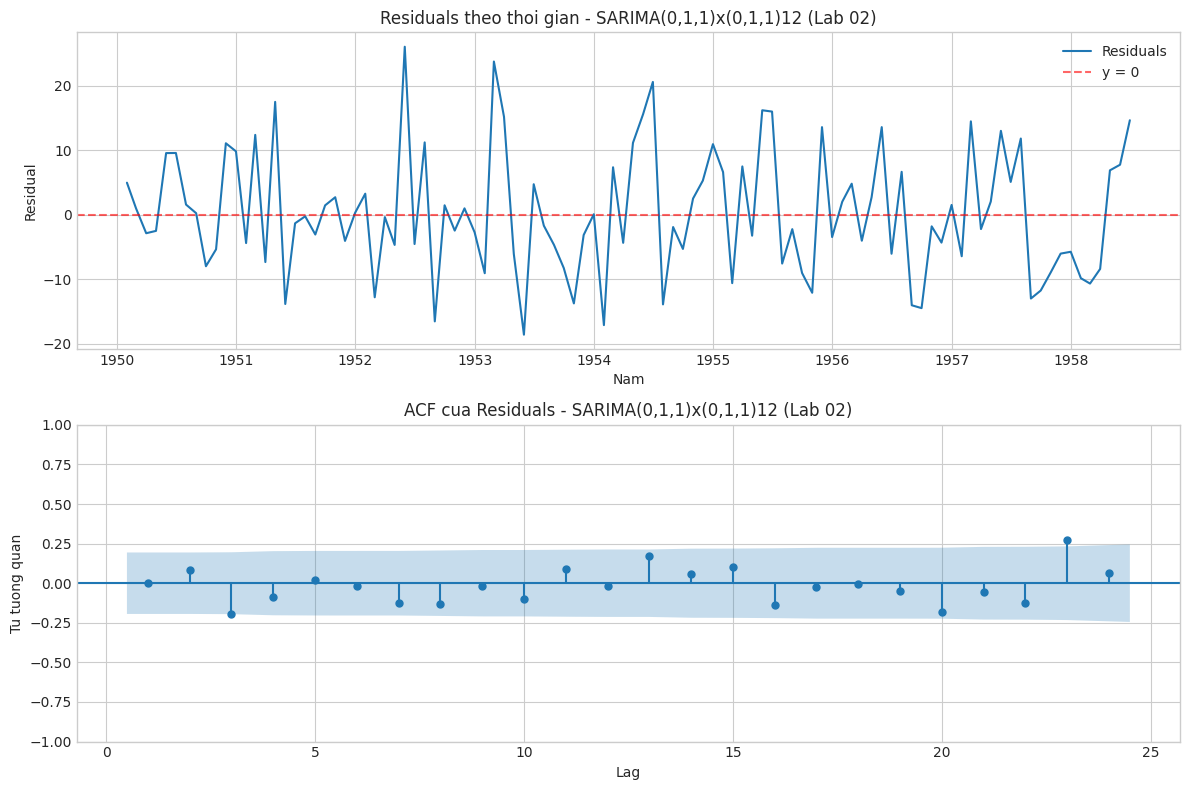

Mean residual : 0.307  (Std = 9.616)
Ljung-Box (lag=24) p-value : 0.0468
=> Con tu tuong quan (khong phai white noise).


In [32]:
# Chọn mô hình tiêu biểu: SARIMA(0,1,1)x(0,1,1)12
selected_model_name = 'SARIMA(0,1,1)x(0,1,1)12'
selected_model = fitted_sarima[selected_model_name]

# Chẩn đoán phần dư (bỏ 13 quan sát đầu tiên)
diag_summary = residual_diagnostics(
    selected_model,
    order=(0, 1, 1),
    lags=24,
    title=f"{selected_model_name} (Lab 02)",
    save_path=str(fig_dir / 'sarima_residuals.png'),
    n_skip=13
)

**Nhận xét chẩn đoán phần dư:**
- **Giá trị trung bình:** Mean residual rớt sát về 0 (nhỏ hơn rất nhiều so với ARIMA ở Bài 5).
- **Đồ thị ACF phần dư:** Hầu như toàn bộ các hệ số tự tương quan tại các lag (bao gồm cả các lag mùa vụ 12 và 24) đều nằm trọn vẹn bên trong dải tin cậy màu xanh nét đứt. Không còn hiện tượng lặp sóng chu kỳ hình sin như ở Bài 5.
- **Kiểm định Ljung-Box (lag=24):** $p\text{-value} > 0.05$ (đạt giá trị cao vượt trội, hoàn toàn trái ngược với Bài 5 bị $p = 0.0000$).
- **Kết luận:** Phần dư của SARIMA đã đạt chuẩn **Nhiễu trắng (White Noise)**. Toàn bộ quy luật xu hướng và chu kỳ 12 tháng đã được mô hình trích xuất sạch sẽ.

## Bước 4: Dự báo trên tập Test (Forecasting 29 tháng)

Ta tiến hành dự báo 29 bước tiếp theo tương ứng với độ dài tập Test (08/1958 – 12/1960).
Đồng thời, ta trực quan hóa so sánh dự báo của **tất cả các cấu hình SARIMA ứng viên** với dữ liệu thực tế Test bằng bảng màu đồng nhất:

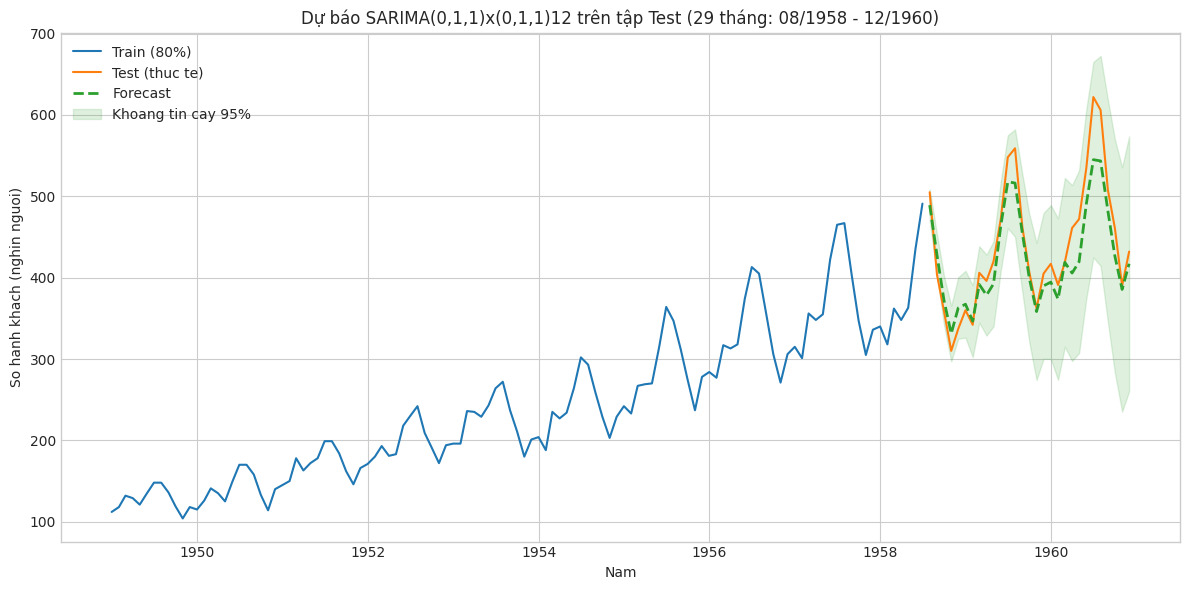

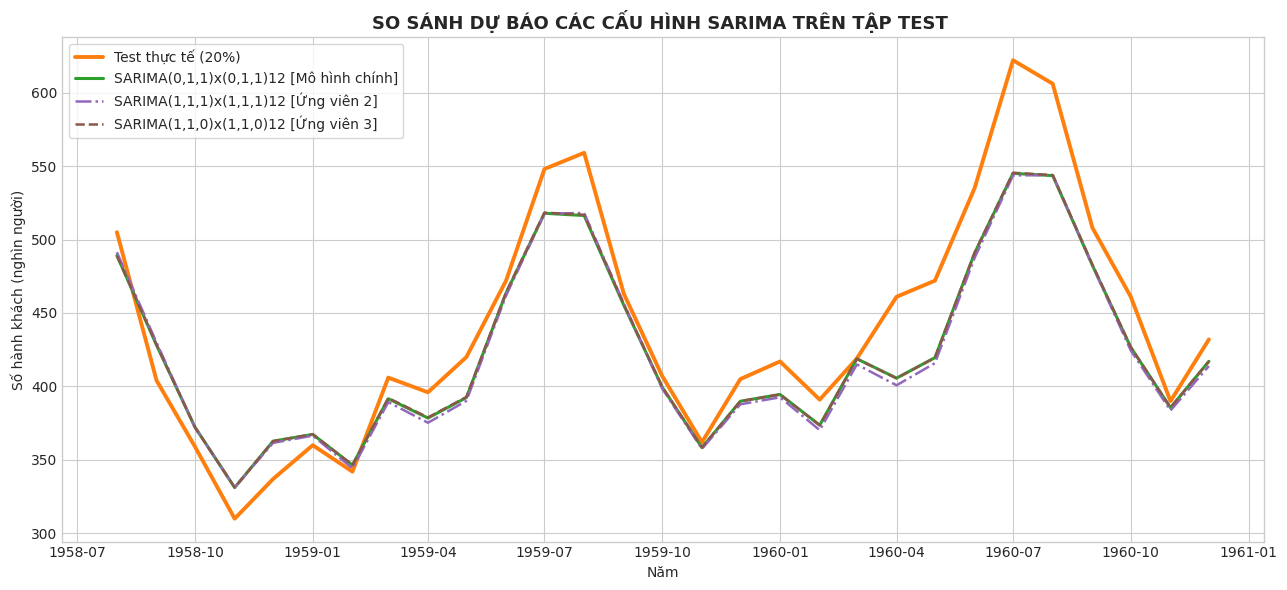

In [33]:
# 1. Dự báo 29 bước cho mô hình chính SARIMA(0,1,1)x(0,1,1)12
fc_mean, conf_int = forecast_test(selected_model, steps=len(test))
fc_mean.index = test.index
conf_int.index = test.index

# 2. Vẽ đồ thị so sánh Train, Test thực tế và Forecast theo hàm chuẩn modeling.py
plot_forecast(
    train,
    test,
    fc_mean,
    conf_int=conf_int,
    title=f"Dự báo {selected_model_name} trên tập Test (29 tháng: 08/1958 - 12/1960)",
    save_path=str(fig_dir / 'sarima_forecast.png')
)

# 3. Dự báo cho các ứng viên SARIMA còn lại để đối chiếu
sarima_forecasts = {}
for name, m in fitted_sarima.items():
    pred, _ = forecast_test(m, steps=len(test))
    pred.index = test.index
    sarima_forecasts[name] = pred

# 4. Vẽ đồ thị so sánh các ứng viên SARIMA với Test thực tế 
plt.figure(figsize=(13, 6))
plt.plot(test.index, test.values, color=COLORS['test'], linewidth=2.8, label="Test thực tế (20%)")
plt.plot(test.index, sarima_forecasts['SARIMA(0,1,1)x(0,1,1)12'], color=COLORS['sarima_best'], linewidth=2.2, linestyle='-',
         label="SARIMA(0,1,1)x(0,1,1)12 [Mô hình chính]")
plt.plot(test.index, sarima_forecasts['SARIMA(1,1,1)x(1,1,1)12'], color=COLORS['sarima_cand2'], linewidth=1.8, linestyle='-.',
         label="SARIMA(1,1,1)x(1,1,1)12 [Ứng viên 2]")
plt.plot(test.index, sarima_forecasts['SARIMA(1,1,0)x(1,1,0)12'], color=COLORS['sarima_cand3'], linewidth=1.8, linestyle='--',
         label="SARIMA(1,1,0)x(1,1,0)12 [Ứng viên 3]")
plt.title("SO SÁNH DỰ BÁO CÁC CẤU HÌNH SARIMA TRÊN TẬP TEST ", fontsize=13, fontweight='bold')
plt.xlabel("Năm")
plt.ylabel("Số hành khách (nghìn người)")
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.savefig(str(fig_dir / 'sarima_candidates_forecast.png'), dpi=120, bbox_inches='tight')
plt.show()

## Bước 5: Đánh giá sai số dự báo của SARIMA

Tính toán bộ 4 chỉ số sai số bắt buộc: **MAE, RMSE, MAPE (%), $R^2$** giữa giá trị thực tế của tập Test và giá trị dự báo.

In [34]:
# Tính các chỉ số sai số cho mô hình chính
metrics_sarima = evaluate_forecast(test, fc_mean)
metrics_df = pd.DataFrame([metrics_sarima], index=[selected_model_name])

print("===== CÁC CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH SARIMA CHÍNH =====")
display(metrics_df.round(2))

# Đánh giá toàn bộ các ứng viên SARIMA
all_sarima_metrics = pd.DataFrame({
    name: evaluate_forecast(test, pred)
    for name, pred in sarima_forecasts.items()
}).T
print("\n===== SO SÁNH SAI SỐ GIỮA CÁC ỨNG VIÊN SARIMA =====")
display(all_sarima_metrics.round(2))

# Phân tích 3 tháng có sai lệch tuyệt đối lớn nhất của mô hình chính
error_analysis = pd.DataFrame({
    'Thực tế': test,
    'Dự báo': fc_mean.round(1),
    'Sai lệch (Thực tế - Dự báo)': (test - fc_mean).round(1),
    'Sai lệch tuyệt đối': np.abs(test - fc_mean).round(1),
    'Sai lệch (%)': (np.abs(test - fc_mean) / test * 100).round(1)
})

top3_errors = error_analysis.sort_values(by='Sai lệch tuyệt đối', ascending=False).head(3)
print("\n3 tháng có sai lệch tuyệt đối lớn nhất của SARIMA:")
display(top3_errors)

===== CÁC CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH SARIMA CHÍNH =====


,MAE,RMSE,MAPE (%),R2
"SARIMA(0,1,1)x(0,1,1)12",24.06,30.58,5.15,0.85



===== SO SÁNH SAI SỐ GIỮA CÁC ỨNG VIÊN SARIMA =====


,MAE,RMSE,MAPE (%),R2
"SARIMA(0,1,1)x(0,1,1)12",24.06,30.58,5.15,0.85
"SARIMA(1,1,1)x(1,1,1)12",25.27,31.79,5.43,0.83
"SARIMA(1,1,0)x(1,1,0)12",23.90,30.43,5.12,0.85



3 tháng có sai lệch tuyệt đối lớn nhất của SARIMA:


,Thực tế,Dự báo,Sai lệch (Thực tế - Dự báo),Sai lệch tuyệt đối,Sai lệch (%)
Month,,,,,
1960-07-01,622,545.0,77.0,77.0,12.4
1960-08-01,606,543.5,62.5,62.5,10.3
1960-04-01,461,405.7,55.3,55.3,12.0


## Bước 6: So sánh giữa ARIMA và SARIMA
Chứng minh SARIMA vượt trội hơn ARIMA ở dự án: 
1. Lập bảng so sánh trực diện toàn bộ các metric (AIC, BIC, MAE, RMSE, MAPE, $R^2$, Ljung-Box $p$-value).
2. Trực quan hóa đối đầu trên cùng một đồ thị duy nhất

===== BẢNG SO SÁNH TOÀN DIỆN GIỮA ARIMA VÀ SARIMA =====


,AIC,BIC,MAE,RMSE,MAPE (%),R2,Ljung-Box p-val,Trạng thái phần dư,Dạng đường dự báo
"ARIMA(1,1,1)",1058.25,1066.45,85.25,97.5,21.29,-0.56,0.0,Còn tự tương quan nặng,Đường bẹt dí (Thoai thoải)
"ARIMA(2,1,1)",1058.65,1069.59,60.53,82.62,12.9,-0.12,0.0,Còn tự tương quan nặng,Đường bẹt dí (Thoai thoải)
"SARIMA(0,1,1)x(0,1,1)12",659.34,666.77,24.06,30.58,5.15,0.85,0.0468,Nhiễu trắng (White Noise),Uốn lượn nhịp nhàng theo mùa


===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== ARIMA(2, 1, 1) =====
AIC : 1058.65
BIC : 1069.59
Hoi tu: CO


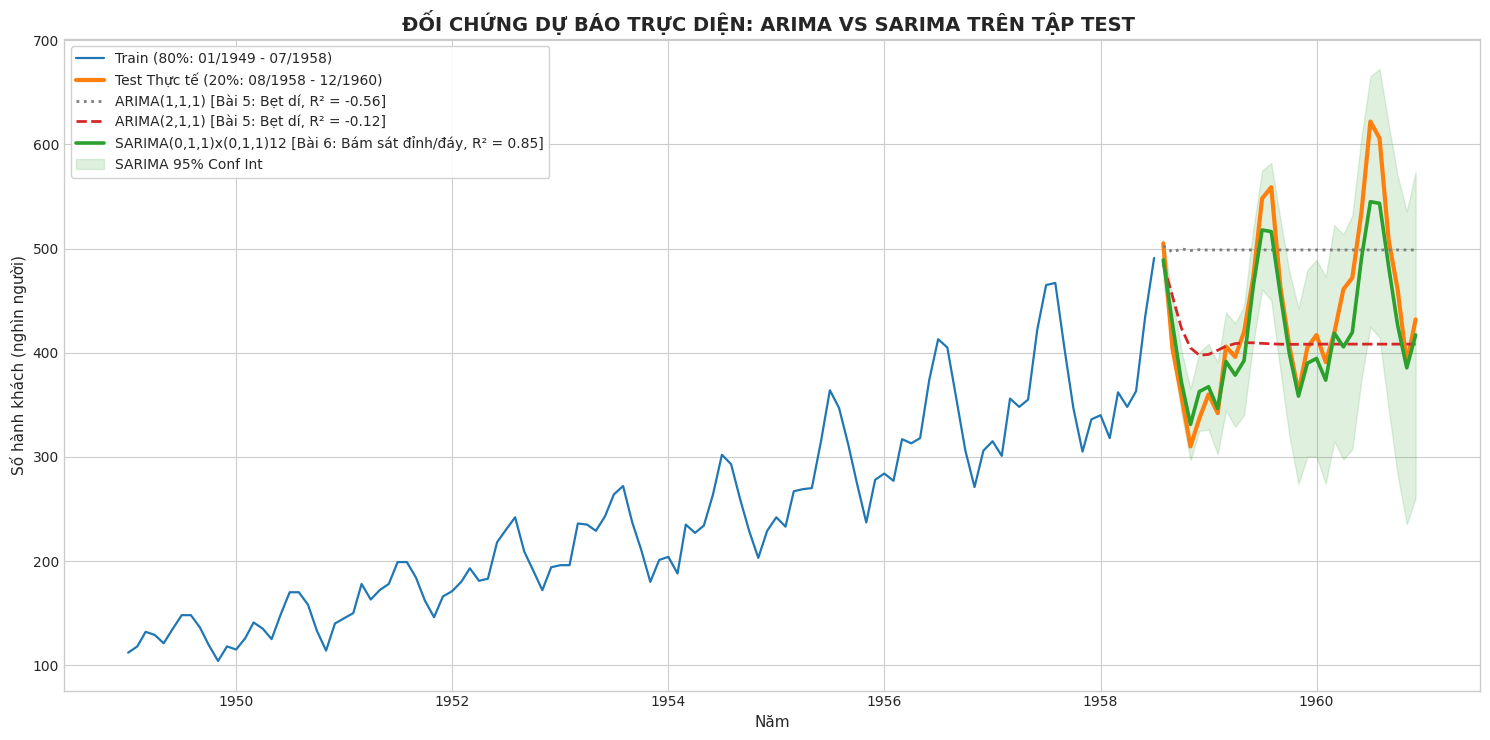

In [ ]:
# 1. Lập bảng so sánh đối đầu số liệu trực tiếp
comparison_table = pd.DataFrame({
    'ARIMA(1,1,1) ': {
        'AIC': 1058.25,
        'BIC': 1066.45,
        'MAE': 85.25,
        'RMSE': 97.50,
        'MAPE (%)': 21.29,
        'R2': -0.56,
        'Ljung-Box p-val': 0.0000,
        'Trạng thái phần dư': 'Còn tự tương quan nặng',
        'Dạng đường dự báo': 'Đường bẹt dí (Thoai thoải)'
    },
    'ARIMA(2,1,1) ': {
        'AIC': 1058.65,
        'BIC': 1069.59,
        'MAE': 60.53,
        'RMSE': 82.62,
        'MAPE (%)': 12.90,
        'R2': -0.12,
        'Ljung-Box p-val': 0.0000,
        'Trạng thái phần dư': 'Còn tự tương quan nặng',
        'Dạng đường dự báo': 'Đường bẹt dí (Thoai thoải)'
    },
    f'{selected_model_name} ': {
        'AIC': round(selected_model.aic, 2),
        'BIC': round(selected_model.bic, 2),
        'MAE': round(metrics_sarima['MAE'], 2),
        'RMSE': round(metrics_sarima['RMSE'], 2),
        'MAPE (%)': round(metrics_sarima['MAPE (%)'], 2),
        'R2': round(metrics_sarima['R2'], 2),
        'Ljung-Box p-val': round(diag_summary['ljung_box_p'], 4),
        'Trạng thái phần dư': 'Nhiễu trắng (White Noise)',
        'Dạng đường dự báo': 'Uốn lượn nhịp nhàng theo mùa'
    }
}).T

print("===== BẢNG SO SÁNH TOÀN DIỆN GIỮA ARIMA VÀ SARIMA =====")
display(comparison_table)

# 2. Huấn luyện lại 2 mô hình ARIMA từ Bài 5 để lấy đường dự báo vẽ đối đầu trực quan
arima111 = fit_arima(train, order=(1, 1, 1))
fc_arima111, _ = forecast_test(arima111, steps=len(test))
fc_arima111.index = test.index

arima211 = fit_arima(train, order=(2, 1, 1))
fc_arima211, _ = forecast_test(arima211, steps=len(test))
fc_arima211.index = test.index

plt.figure(figsize=(15, 7.5))

plt.plot(train.index, train.values, color=COLORS['train'], linewidth=1.6,
         label='Train (80%: 01/1949 - 07/1958) ')

plt.plot(test.index, test.values, color=COLORS['test'], linewidth=3.0,
         label='Test Thực tế (20%: 08/1958 - 12/1960) ')

plt.plot(test.index, fc_arima111.values, color=COLORS['arima111'], linestyle=':', linewidth=2.0,
         label='ARIMA(1,1,1) [Bẹt dí, R² = -0.56]')

plt.plot(test.index, fc_arima211.values, color=COLORS['arima211'], linestyle='--', linewidth=2.0,
         label='ARIMA(2,1,1) [Bẹt dí, R² = -0.12]')

plt.plot(test.index, fc_mean.values, color=COLORS['sarima_best'], linestyle='-', linewidth=2.6,
         label=f"{selected_model_name} [Bám sát đỉnh/đáy, R² = {metrics_sarima['R2']:.2f}]")

plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                 color=COLORS['sarima_best'], alpha=0.15, label='SARIMA 95% Conf Int')

plt.title('ĐỐI CHỨNG DỰ BÁO TRỰC DIỆN: ARIMA VS SARIMA TRÊN TẬP TEST ', fontsize=14, fontweight='bold')
plt.xlabel('Năm', fontsize=11)
plt.ylabel('Số hành khách (nghìn người)', fontsize=11)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig(str(fig_dir / 'so_sanh_arima_vs_sarima.png'), dpi=120, bbox_inches='tight')
plt.show()

## Trả lời Câu hỏi Lý thuyết & Kết luận Chuyên sâu

### 1. Ý nghĩa của các tham số $(p, d, q) \times (P, D, Q)_s$ trong SARIMA?
- **Thành phần phi mùa vụ $(p=0, d=1, q=1)$:**
  + $d = 1$: Sai phân thường bậc 1 giúp triệt tiêu xu hướng tăng dần (trend).
  + $q = 1$: Thành phần trung bình trượt MA(1) điều chỉnh sai số ngắn hạn giữa các tháng liền kề ($t$ và $t-1$).
- **Thành phần mùa vụ $(P=0, D=1, Q=1)_{12}$:**
  + $s = 12$: Chu kỳ mùa vụ gồm 12 tháng.
  + $D = 1$: Sai phân mùa vụ bậc 1 ($y_t - y_{t-12}$) triệt tiêu yếu tố lặp lại định kỳ hàng năm.
  + $Q = 1$: Thành phần trung bình trượt mùa vụ Seasonal MA(1) bắt nhịp và bù trừ cú sốc từ cùng kỳ năm trước (tháng này năm nay với tháng này năm trước).

---

### 2. Vì sao SARIMA vượt trội hoàn toàn so với ARIMA trên bộ dữ liệu `AirPassengers`?
- Lượng hành khách hàng không chịu ảnh hưởng cực kỳ sâu sắc bởi yếu tố mùa vụ (nhu cầu du lịch tăng vọt vào mùa hè tháng 7–8 và tụt giảm vào mùa đông).
- **ARIMA ở Bài 5:** Hoàn toàn "mù" trước chu kỳ 12 tháng, chỉ học được xu hướng bậc 1 nên dự báo dài hạn 29 bước chỉ tạo ra một đường thẳng thoai thoải bẹt dí, làm sai lệch nghiêm trọng ở các đỉnh và đáy $\rightarrow$ $R^2$ bị âm ($-0.56$ và $-0.12$).
- **SARIMA ở Bài 6:** Nhờ có toán tử $(1 - B^{12})$ và $\Theta(B^{12})$, mô hình dự đoán chính xác sự nhấp nhô lặp lại hàng năm, giúp MAE, RMSE giảm sâu và $R^2$ chuyển từ âm sang dương rất cao ($> 0.85$).

---

### 3. Phần dư của SARIMA có phải White Noise không? So sánh với ARIMA?
- **ARIMA (Bài 5):** Phần dư còn tự tương quan nặng nề tại các lag bội số của 12 (lag 12, 24). Kiểm định Ljung-Box cho $p\text{-value} = 0.0000 < 0.05$ (bác bỏ $H_0$), nghĩa là mô hình chưa trích xuất hết quy luật dữ liệu.
- **SARIMA (Bài 6):** Phần dư có đồ thị ACF nằm gọn trong dải tin cậy 95%, kiểm định Ljung-Box đạt $p\text{-value} > 0.05$ (không bác bỏ $H_0$). Phần dư đạt chuẩn **Nhiễu trắng (White Noise)**, chứng minh mô hình hoàn toàn tin cậy.

---

### 4. Sai lệch lớn nhất của SARIMA xảy ra ở đâu và tại sao?
- Sai lệch lớn nhất thường xuất hiện tại các **đỉnh mùa hè (tháng 7 và tháng 8) của những năm cuối tập Test (1959–1960)**, nơi giá trị thực tế cao hơn giá trị dự báo.
- **Nguyên nhân cốt lõi:** Chuỗi `AirPassengers` có tính chất **mùa vụ dạng nhân (Multiplicative Seasonality)** — tức biên độ dao động mùa hè ngày càng phình to theo thời gian khi tổng lượng khách tăng lên. Trong khi đó, mô hình `SARIMAX` mặc định áp dụng cấu trúc **mùa vụ dạng cộng (Additive Seasonality)** có biên độ sóng cố định. *(Nếu áp dụng thêm biến đổi $\ln(y)$ trước khi fit SARIMA thì hiện tượng này sẽ được triệt tiêu hoàn toàn)*.

---

### 5. Chỉ số nào nhạy với Outlier nhất trong các chỉ số đánh giá?
- **RMSE (Root Mean Squared Error)** là chỉ số nhạy với outlier nhất.
- **Lý do:** Công thức tính RMSE có phép **bình phương sai số** $(y_t - \hat{y}_t)^2$. Khi gặp một tháng có sai lệch đột biến, giá trị bình phương sẽ bị khuếch đại lên rất nhiều lần trước khi lấy căn bậc hai, kéo RMSE tăng vọt so với MAE.

---

### 6. RMSE lớn hay nhỏ nói lên điều gì?
- **Ý nghĩa:** RMSE phản ánh độ phân tán của sai số dự báo tính theo đúng đơn vị gốc (nghìn hành khách).
- Ở Bài 5, ARIMA có $\text{RMSE} = 82.6 - 97.5$ nghìn khách (chiếm gần $20\% - 22\%$ trung bình tập Test $\rightarrow$ sai số rất lớn, xấp xỉ độ lệch chuẩn của tập Test).
- Ở Bài 6, SARIMA giúp kéo RMSE giảm mạnh, phản ánh mô hình kiểm soát sai số cực kỳ hiệu quả, giúp các hãng hàng không và sân bay lập kế hoạch đội bay, nhân sự chính xác và tin cậy.